# 03 · Modelos, evaluación y discusión

**Machine Learning 1 · FIUNA · 2026**  
Hugo Rene Caniza Portillo y Ruben Dario Lopez Sanabria

Presentamos el experimento definitivo aprobado: regresión logística y Random Forest, dos ventanas y dos horizontes, con diez predictores meteorológicos. Reutilizamos modelos, búsquedas y predicciones guardadas. **No ejecutamos GridSearchCV ni nuevos ajustes al ejecutar este notebook.**

El notebook es independiente y requiere `requirements.txt`, los resultados agregados públicos en `results/` y `results/academicos/`. La evaluación de enero–marzo de 2026 ya había sido observada; la llamamos **evaluación histórica**, sin presentarla como una prueba inédita. La selección está congelada y solo usa validación. Las cifras históricas siguientes se discuten sin cambiar modelos, variables, ventanas, umbral o particiones.

Esta evaluación se ejecuta sin `data/`, sin modelos serializados y sin predicciones individuales. Las curvas exportadas contienen únicamente coordenadas agregadas, sin umbrales ni identificadores. Para reproducir el entrenamiento completo sí se requieren los insumos originales autorizados.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Funciona tanto desde la raíz del proyecto como desde notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'scripts/proyecto.json').is_file() and (p / 'scripts').is_dir())
sys.path.insert(0, str(ROOT / 'scripts'))
from procesar_datos import FEATURES, AGGREGATIONS, configured, sha, verify_samples

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 24)

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

## 1. Resultados oficiales y trazabilidad

Leemos las métricas aprobadas y los agregados exportados. Comprobamos que la selección coincide con su manifiesto y que las matrices de confusión reproducen F1, precisión y recall. La verificación completa de predicciones y modelos permanece en los scripts técnicos y no es necesaria para visualizar esta entrega.

In [2]:
frozen = read_json(configured('resultados') / 'seleccion.json')
timeline = read_json(configured('resultados') / 'secuencia.json')
comparison = pd.read_csv(configured('resultados') / 'comparacion.csv')
scores = pd.read_csv(configured('resultados') / 'metricas.csv', dtype={'fold': str})
learning = pd.read_csv(configured('resultados') / 'aprendizaje.csv')
curves = read_json(configured('resultados') / 'academicos/curvas.json')
manifest = read_json(configured('resultados') / 'academicos/manifiesto.json')
assert manifest['seleccion_sha256'] == sha(configured('resultados') / 'seleccion.json')
for name, digest in manifest['salidas'].items():
    assert sha(configured('resultados') / 'academicos' / name) == digest
config = read_json(ROOT / 'scripts/proyecto.json')['experimento']
assert config == frozen['config']
for row in comparison.itertuples():
    tp, fp, fn = row.historico_tp, row.historico_fp, row.historico_fn
    assert np.isclose(row.historico_f1, 2*tp/(2*tp+fp+fn) if tp else 0)
    assert np.isclose(row.historico_precision, tp/(tp+fp) if tp+fp else 0)
    assert np.isclose(row.historico_recall, tp/(tp+fn))
display(comparison[['config','historico_n','historico_f1']].round(4))
display(pd.Series(read_json(configured('resultados') / 'entorno.json')).loc[
    ['python','numpy','pandas','sklearn','joblib']].to_frame('entorno del ajuste aprobado'))

,config,historico_n,historico_f1
0,LR_14d_h0,66.0,0.3774
1,LR_14d_h7,46.0,0.4848
2,LR_7d_h0,66.0,0.3265
3,LR_7d_h7,46.0,0.4444
4,RF_14d_h0,66.0,0.3200
5,RF_14d_h7,46.0,0.3429
6,RF_7d_h0,66.0,0.3846
7,RF_7d_h7,46.0,0.4444
8,mayoria_h0,66.0,0.0000
9,mayoria_h7,46.0,0.0000


,entorno del ajuste aprobado
python,3.10.11
numpy,2.1.3
pandas,2.2.3
sklearn,1.6.1
joblib,1.5.0


Los agregados conservan las métricas aprobadas. Los conteos reproducen F1, precisión y recall y los hashes vinculan las curvas con la selección congelada. ROC AUC y AP se conservan de la evaluación oficial; no se recalculan aproximando el área del gráfico. La secuencia original de congelación y evaluación permanece registrada en `results/secuencia.json`.

## 2. Entrada → salida y modelos

La entrada contiene únicamente los diez resúmenes meteorológicos calculados entre t−w y t−1, con w igual a 7 o 14. La salida es una puntuación para la clase positiva y una clase con umbral **0,5**. En h0 la etiqueta está registrada en t; en h7 está registrada exactamente en t+7. Identificadores, coordenadas, fechas y `resultado_t` no entran en LR/RF.

- **Regresión logística (LR):** `StandardScaler → LogisticRegression`. El escalador se ajusta dentro de cada entrenamiento temporal. C controla la regularización inversa; usamos un máximo de 3.000 iteraciones.
- **Random Forest (RF):** 300 árboles, sin necesidad de escalado. Limitamos profundidad y mínimo por hoja según la grilla aprobada.
- **Mayoría:** se calcula con las etiquetas de cada entrenamiento; en empate predice negativo. Su puntuación constante es la proporción positiva de entrenamiento.
- **Persistencia h7:** usa el resultado registrado en t como predicción del de t+7. Es una referencia que dispone de información de estado que los modelos meteorológicos no usan. Su disponibilidad operacional tampoco está acreditada.

Mostramos la estructura y los parámetros de los pipelines seleccionados a partir de la configuración congelada, sin cargar ni ajustar modelos.

In [3]:
display(pd.DataFrame({'variable': FEATURES, 'unidad': ['%']*3 + ['°C']*3 + ['mm'] + ['m/s']*3}))
pipelines = pd.DataFrame(frozen['configs'])
pipelines = pipelines[pipelines.apply(lambda row: frozen['selected'][str(row.horizonte)] == row.config, axis=1)].copy()
pipelines['pipeline'] = pipelines.modelo.map({'LR': 'StandardScaler → LogisticRegression', 'RF': 'RandomForestClassifier (300 árboles)'})
display(pipelines[['config','pipeline','parametros']])

,variable,unidad
0,hr_media_pct,%
1,hr_min_pct,%
2,hr_max_pct,%
3,temperatura_media_c,°C
4,temperatura_min_c,°C
5,temperatura_max_c,°C
6,precipitacion_mm,mm
7,viento_vel_media_10m_ms,m/s
8,viento_u_media_10m_ms,m/s
9,viento_v_media_10m_ms,m/s


,config,pipeline,parametros
1,RF_7d_h0,RandomForestClassifier (300 árboles),"{'model__max_depth': 3, 'model__min_samples_le..."
6,LR_14d_h7,StandardScaler → LogisticRegression,{'model__C': 10}


El contrato de entrada es el mismo para todos los modelos: diez variables y el mismo orden. Cambian horizonte, ventana y algoritmo. Persistencia ayuda a evaluar si el clima agrega valor frente a mantener el estado conocido, pero no equivale a una alerta agronómica validada.

## 3. Validación temporal e hiperparámetros

Usamos tres folds crecientes, cada uno con seis fechas semanales de etiqueta, y purga de 14 días respecto de la primera referencia validada. Para h7 la etiqueta futura de entrenamiento también debe respetar esa separación. Los entrenamientos/validaciones son 164/38, 188/55 y 239/100 en h0; 141/31, 150/51 y 196/90 en h7.

GridSearchCV optimizó F1 de positivos en esos folds. Semilla 42, umbral 0,5 y grillas fijas. Las tres medias de CV son descriptivas y sus bloques no son experimentos independientes. La búsqueda y selección sobre los mismos folds pueden hacer optimista el resultado de validación; no es validación anidada.

In [4]:
summary = pd.read_csv(configured('resultados') / 'academicos/particiones.csv', dtype={'bloque': str})
columns = ['horizonte', 'bloque', 'rol', 'n', 'negativos', 'positivos', 'ubicaciones',
           'etiqueta_inicio', 'etiqueta_fin', 'referencia_inicio', 'referencia_fin',
           'dias_inclusivos', 'fechas_observadas']
display(summary.loc[summary.bloque.ne('historico'), columns].fillna('—'))
display(pd.DataFrame([
    ['LR', 'C', config['lr_c']], ['RF', 'n_estimators', config['rf_n_estimators']],
    ['RF', 'max_depth', config['rf_max_depth']], ['RF', 'min_samples_leaf', config['rf_min_samples_leaf']],
    ['Ambos', 'semilla', config['seed']], ['Ambos', 'umbral', config['threshold']],
], columns=['modelo', 'parámetro', 'valores']))
grids = []
for record in frozen['configs']:
    grid = pd.read_csv(configured('resultados') / 'busquedas' / f"{record['config']}.csv")
    grid.insert(0, 'config', record['config'])
    grids.append(grid[['config', 'params', 'mean_test_score', 'std_test_score', 'rank_test_score']])
display(pd.concat(grids, ignore_index=True).round(4))

,horizonte,bloque,rol,n,negativos,positivos,ubicaciones,etiqueta_inicio,etiqueta_fin,referencia_inicio,referencia_fin,dias_inclusivos,fechas_observadas
3,0,1,entrenamiento,164,78.0,86.0,17.0,2024-09-02,2025-01-06,2024-09-02,2025-01-06,127.0,18.0
4,0,1,validacion,38,23.0,15.0,8.0,2025-08-18,2025-09-22,2025-08-18,2025-09-22,36.0,6.0
5,0,1,purga,2,2.0,0.0,2.0,2025-08-11,2025-08-11,2025-08-11,2025-08-11,1.0,1.0
6,0,2,entrenamiento,188,95.0,93.0,17.0,2024-09-02,2025-09-08,2024-09-02,2025-09-08,372.0,23.0
7,0,2,validacion,55,29.0,26.0,12.0,2025-09-29,2025-11-03,2025-09-29,2025-11-03,36.0,6.0
8,0,2,purga,16,8.0,8.0,8.0,2025-09-15,2025-09-22,2025-09-15,2025-09-22,8.0,2.0
9,0,3,entrenamiento,239,120.0,119.0,18.0,2024-09-02,2025-10-20,2024-09-02,2025-10-20,414.0,29.0
10,0,3,validacion,100,56.0,44.0,19.0,2025-11-10,2025-12-15,2025-11-10,2025-12-15,36.0,6.0
11,0,3,purga,20,12.0,8.0,12.0,2025-10-27,2025-11-03,2025-10-27,2025-11-03,8.0,2.0
15,7,1,entrenamiento,141,62.0,79.0,17.0,2024-09-09,2024-12-23,2024-09-02,2024-12-16,106.0,16.0


,modelo,parámetro,valores
0,LR,C,"[0.1, 1, 10]"
1,RF,n_estimators,300
2,RF,max_depth,"[3, 5, None]"
3,RF,min_samples_leaf,"[3, 5, 10]"
4,Ambos,semilla,42
5,Ambos,umbral,0.5


,config,params,mean_test_score,std_test_score,rank_test_score
0,LR_7d_h0,{'model__C': 0.1},0.6016,0.0722,1
1,LR_7d_h0,{'model__C': 1},0.5859,0.0739,2
2,LR_7d_h0,{'model__C': 10},0.5833,0.0696,3
3,RF_7d_h0,"{'model__max_depth': 3, 'model__min_samples_le...",0.5969,0.0679,8
4,RF_7d_h0,"{'model__max_depth': 3, 'model__min_samples_le...",0.5888,0.0710,9
5,RF_7d_h0,"{'model__max_depth': 3, 'model__min_samples_le...",0.6289,0.1018,1
6,RF_7d_h0,"{'model__max_depth': 5, 'model__min_samples_le...",0.6209,0.0647,5
7,RF_7d_h0,"{'model__max_depth': 5, 'model__min_samples_le...",0.6120,0.0644,6
8,RF_7d_h0,"{'model__max_depth': 5, 'model__min_samples_le...",0.6229,0.0832,2
9,RF_7d_h0,"{'model__max_depth': None, 'model__min_samples...",0.6118,0.0687,7


Cada bloque abarca 35 días transcurridos y 36 incluyendo los extremos, con seis observaciones semanales de fecha. El primer fold prueba transferencia desde la campaña anterior. No confundimos la purga con una prueba de disponibilidad operacional: no contamos con fechas de publicación verificadas para todas las etiquetas.

## 4. Resultados de validación y selección congelada

Seleccionamos por **F1 medio de positivos**. Ante empate a tres decimales, preferimos 7 días y luego LR; todas las configuraciones tienen diez variables. El F1 combina precisión y recall, pero no refleja por sí solo el costo agronómico de omitir un positivo. Mostramos también cada fold y la variabilidad entre bloques.

,config,horizonte,ventana,parametros,cv_f1,cv_std,seleccionado
0,LR_7d_h0,0,7,{'model__C': 0.1},0.6016,0.0722,False
1,RF_7d_h0,0,7,"{'model__max_depth': 3, 'model__min_samples_le...",0.6289,0.1018,True
2,LR_14d_h0,0,14,{'model__C': 10},0.6217,0.0262,False
3,RF_14d_h0,0,14,"{'model__max_depth': 5, 'model__min_samples_le...",0.6159,0.0567,False
4,LR_7d_h7,7,7,{'model__C': 1},0.5744,0.0830,False
5,RF_7d_h7,7,7,"{'model__max_depth': None, 'model__min_samples...",0.5969,0.0956,False
6,LR_14d_h7,7,14,{'model__C': 10},0.6312,0.0541,True
7,RF_14d_h7,7,14,"{'model__max_depth': None, 'model__min_samples...",0.6143,0.0656,False


fold,1,2,3
config,,,
LR_14d_h0,0.5854,0.6462,0.6337
LR_14d_h7,0.5946,0.7077,0.5913
LR_7d_h0,0.6047,0.6885,0.5116
LR_7d_h7,0.4865,0.6857,0.5510
RF_14d_h0,0.5405,0.6774,0.6296
RF_14d_h7,0.6061,0.6984,0.5385
RF_7d_h0,0.7000,0.7018,0.4848
RF_7d_h7,0.5714,0.7246,0.4946
mayoria_h0,0.5660,0.0000,0.0000


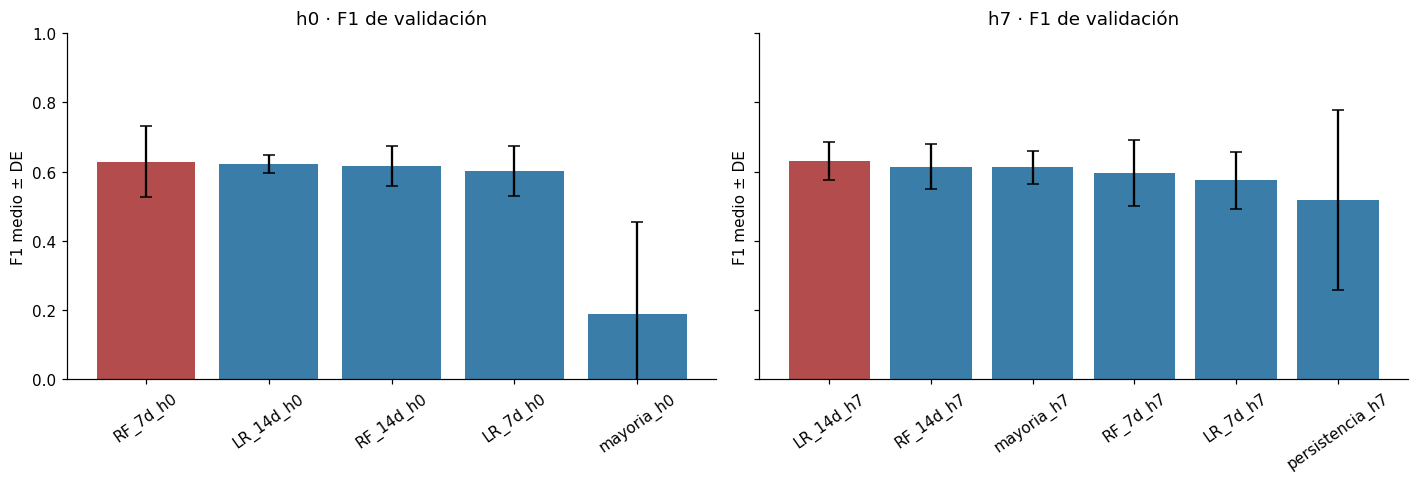

In [5]:
selected_table = pd.DataFrame(frozen['configs'])
selected_table['seleccionado'] = selected_table.apply(
    lambda row: frozen['selected'][str(row.horizonte)] == row.config, axis=1)
display(selected_table[['config', 'horizonte', 'ventana', 'parametros', 'cv_f1', 'cv_std', 'seleccionado']].round(4))
cv = scores[scores.rol.eq('validacion')]
display(cv.pivot(index='config', columns='fold', values='f1').round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for h, ax in zip([0, 7], axes):
    table = comparison[comparison.horizonte.eq(h)].sort_values('cv_f1', ascending=False)
    colors = ['#b34d4d' if name == frozen['selected'][str(h)] else '#397da8' for name in table.config]
    ax.bar(table.config, table.cv_f1, yerr=table.cv_std, capsize=4, color=colors)
    ax.set(title=f'h{h} · F1 de validación', ylabel='F1 medio ± DE', ylim=(0, 1))
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

La selección aprobada es **RF de 7 días para h0** (F1 medio ≈0,629; profundidad 3 y mínimo 10 por hoja) y **LR de 14 días para h7** (F1 medio ≈0,631; C=10). Las barras de dispersión son desviaciones estándar descriptivas de tres folds, no intervalos de confianza. Estos modelos se mantienen aunque otro obtenga una cifra histórica más favorable.

## 5. Comparación histórica de las ocho configuraciones y referencias

El período histórico contiene 66 muestras h0 (29 negativas y 37 positivas) y 46 h7 (22 negativas y 24 positivas). Mostramos todas las configuraciones para hacer transparente el experimento; **no elegimos una nueva ganadora a partir de esta tabla**. H0 y h7 no comparten exactamente población ni tarea.

Precisión, recall y F1 corresponden a la clase positiva; ROC AUC evalúa ordenación y average precision (AP) resume la curva de precisión–recall. Ninguna métrica demuestra calibración probabilística. La accuracy puede ocultar fallos de la clase positiva.

In [6]:
historical_columns = ['config', 'horizonte', 'ventana', 'seleccionado', 'cv_f1', 'cv_std',
    'historico_n', 'historico_f1', 'historico_precision', 'historico_recall',
    'historico_accuracy', 'historico_balanced_accuracy', 'historico_roc_auc', 'historico_average_precision']
display(comparison[historical_columns].sort_values(['horizonte', 'ventana', 'config']).round(4))
chosen = comparison[comparison.seleccionado].copy()
display(chosen[['config', 'historico_tn', 'historico_fp', 'historico_fn', 'historico_tp']].astype(
    {'historico_tn': int, 'historico_fp': int, 'historico_fn': int, 'historico_tp': int}))

,config,horizonte,ventana,seleccionado,cv_f1,cv_std,historico_n,historico_f1,historico_precision,historico_recall,historico_accuracy,historico_balanced_accuracy,historico_roc_auc,historico_average_precision
8,mayoria_h0,0,0,False,0.1887,0.2668,66.0,0.0000,0.0000,0.0000,0.4394,0.5000,0.5000,0.5606
2,LR_7d_h0,0,7,False,0.6016,0.0722,66.0,0.3265,0.6667,0.2162,0.5000,0.5391,0.6608,0.6476
6,RF_7d_h0,0,7,True,0.6289,0.1018,66.0,0.3846,0.6667,0.2703,0.5152,0.5489,0.6486,0.6947
0,LR_14d_h0,0,14,False,0.6217,0.0262,66.0,0.3774,0.6250,0.2703,0.5000,0.5317,0.5648,0.6594
4,RF_14d_h0,0,14,False,0.6159,0.0567,66.0,0.3200,0.6154,0.2162,0.4848,0.5219,0.7148,0.6819
9,mayoria_h7,7,0,False,0.6127,0.0482,46.0,0.0000,0.0000,0.0000,0.4783,0.5000,0.5000,0.5217
10,persistencia_h7,7,0,False,0.5180,0.2614,46.0,0.7347,0.7200,0.7500,0.7174,0.7159,0.7159,0.6704
3,LR_7d_h7,7,7,False,0.5744,0.0830,46.0,0.4444,0.6667,0.3333,0.5652,0.5758,0.4886,0.6207
7,RF_7d_h7,7,7,False,0.5969,0.0956,46.0,0.4444,0.6667,0.3333,0.5652,0.5758,0.5739,0.6348
1,LR_14d_h7,7,14,True,0.6312,0.0541,46.0,0.4848,0.8889,0.3333,0.6304,0.6439,0.4640,0.6225


,config,historico_tn,historico_fp,historico_fn,historico_tp
1,LR_14d_h7,21,1,16,8
6,RF_7d_h0,24,5,27,10


El RF seleccionado para h0 alcanza F1 ≈0,385 y detecta 10 de 37 positivos (recall ≈0,270). La LR seleccionada para h7 alcanza F1 ≈0,485 y detecta 8 de 24 (recall ≈0,333), con precisión ≈0,889. Esa precisión se obtiene identificando pocos positivos: no compensa automáticamente el elevado número de omisiones. La caída respecto de CV limita la evidencia de generalización temporal.

## 6. Matrices de confusión

Dibujamos los conteos de las ocho configuraciones y las referencias. Filas: clase real. Columnas: clase predicha. Los títulos indican la selección congelada. Mantener los conteos permite reconocer el tamaño pequeño de cada evaluación.

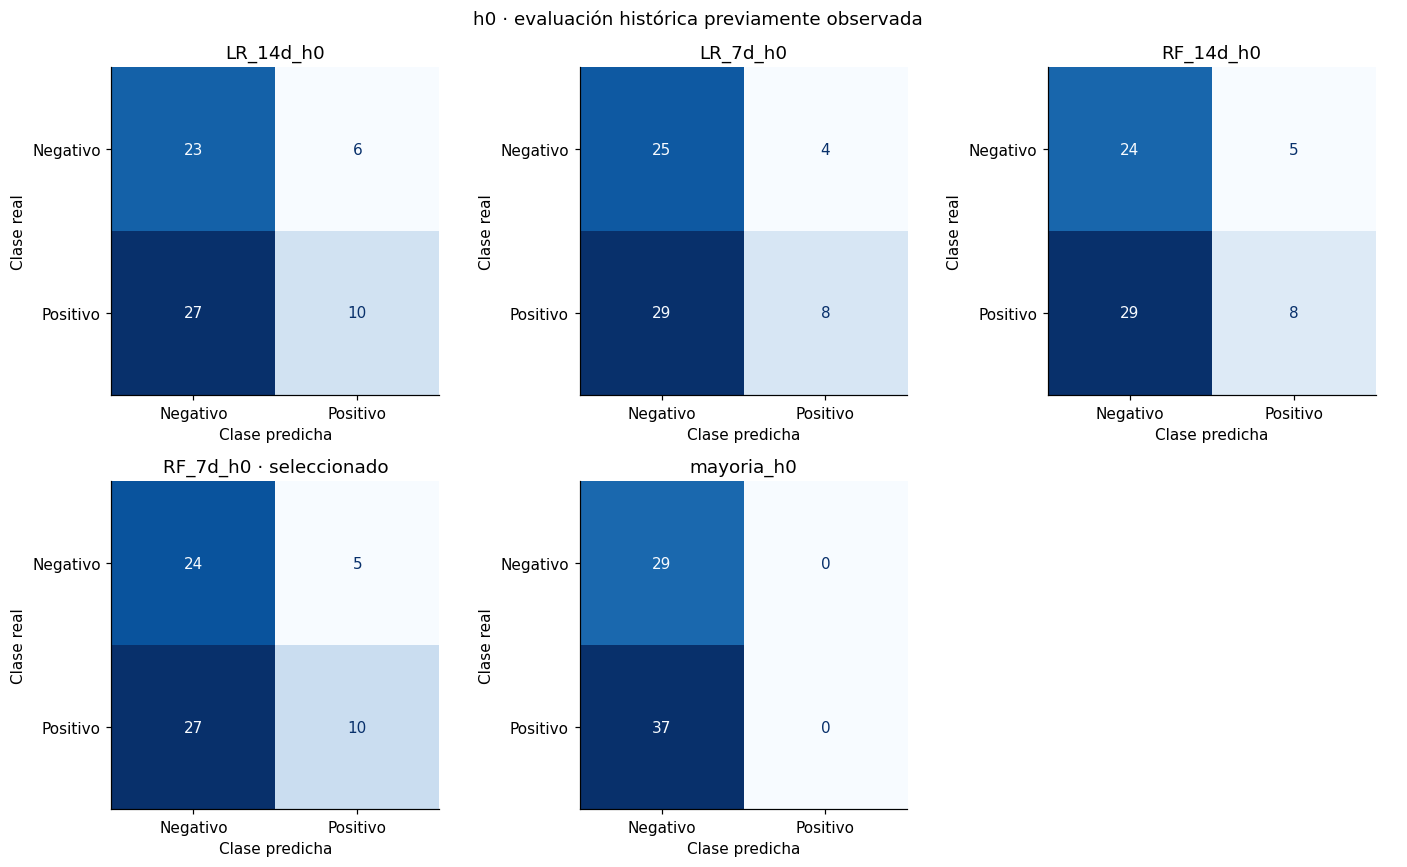

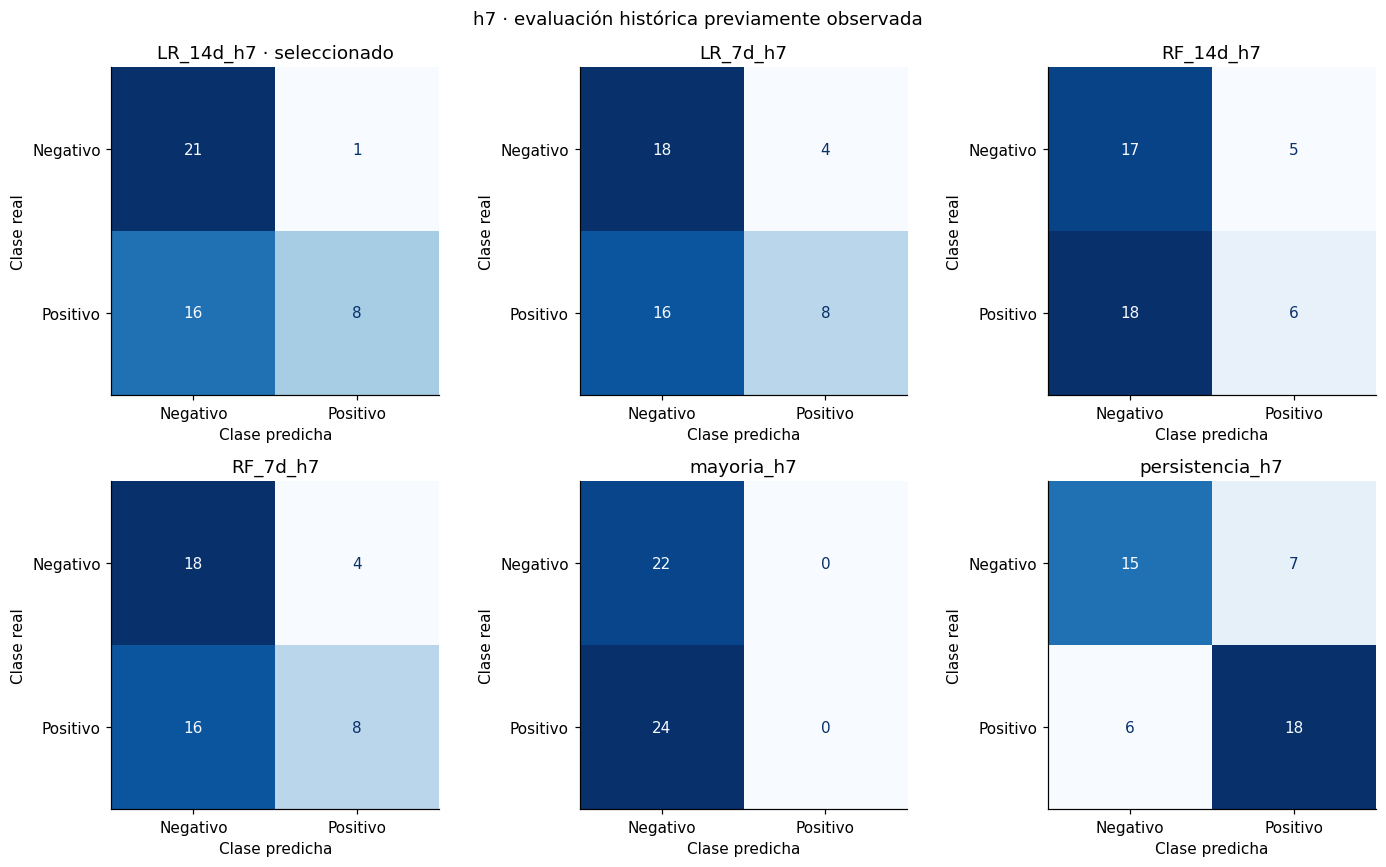

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay
for h in [0, 7]:
    table = comparison[comparison.horizonte.eq(h)]
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    for row, ax in zip(table.itertuples(), axes.flat):
        matrix = np.array([[row.historico_tn, row.historico_fp], [row.historico_fn, row.historico_tp]], dtype=int)
        ConfusionMatrixDisplay(matrix, display_labels=['Negativo','Positivo']).plot(ax=ax, colorbar=False, cmap='Blues')
        ax.set(title=row.config + (' · seleccionado' if row.seleccionado else ''), xlabel='Clase predicha', ylabel='Clase real')
    for ax in list(axes.flat)[len(table):]: ax.axis('off')
    fig.suptitle(f'h{h} · evaluación histórica previamente observada')
    plt.tight_layout()
    plt.show()

Los modelos seleccionados omiten 27 positivos en h0 y 16 en h7. La mayoría no predice positivos en estos entrenamientos históricos y, por tanto, su F1 positivo es cero. En h7, persistencia detecta 18 de los 24 positivos; su matriz aporta un contraste más exigente que la mayoría para esta tarea.

## 7. Curvas ROC y Precision–Recall

Usamos las coordenadas de curvas exportadas desde las puntuaciones históricas oficiales, sin modificar el umbral 0,5. Mostramos todas las configuraciones y referencias por horizonte. La diagonal de ROC representa ordenación aleatoria; la línea horizontal de PR representa la proporción positiva observada del bloque. No ajustamos umbrales a partir de estas curvas.

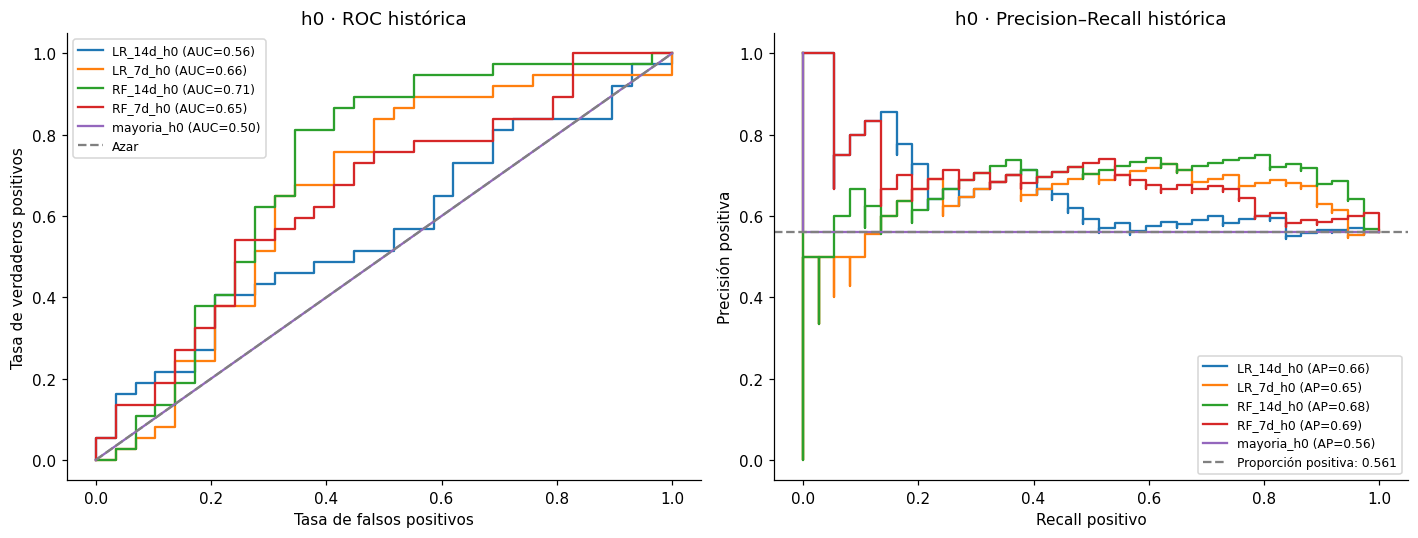

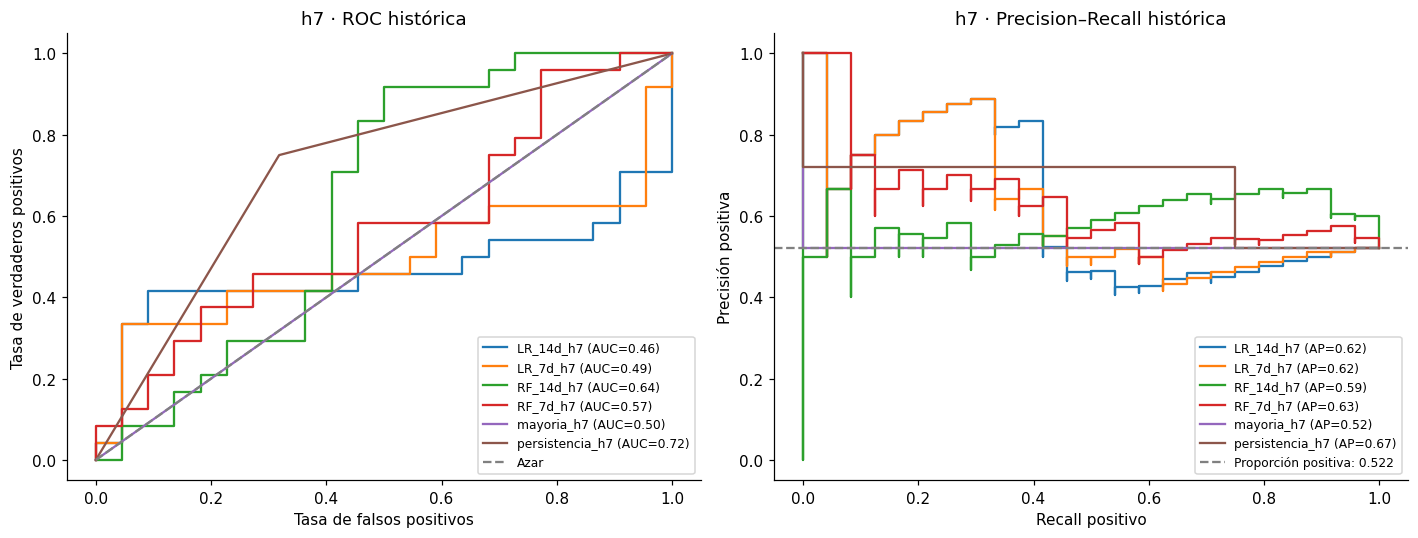

In [8]:
for h in [0, 7]:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for curve in [c for c in curves if c['horizonte'] == h]:
        row = comparison.set_index('config').loc[curve['config']]
        axes[0].plot(curve['fpr'], curve['tpr'], label=f"{curve['config']} (AUC={row.historico_roc_auc:.2f})")
        axes[1].step(curve['recall'], curve['precision'], where='post', label=f"{curve['config']} (AP={row.historico_average_precision:.2f})")
    row = comparison[comparison.horizonte.eq(h)].iloc[0]
    prevalence = (row.historico_tp + row.historico_fn)/row.historico_n
    axes[0].plot([0,1],[0,1],'--',color='gray',label='Azar')
    axes[1].axhline(prevalence,ls='--',color='gray',label=f'Proporción positiva: {prevalence:.3f}')
    axes[0].set(title=f'h{h} · ROC histórica',xlabel='Tasa de falsos positivos',ylabel='Tasa de verdaderos positivos')
    axes[1].set(title=f'h{h} · Precision–Recall histórica',xlabel='Recall positivo',ylabel='Precisión positiva')
    for ax in axes: ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

Las curvas son escalonadas porque los conjuntos históricos son pequeños. AP y ROC AUC resumen aspectos distintos: una precisión elevada en el umbral elegido puede coexistir con una ordenación global débil. Por ejemplo, la LR seleccionada para h7 tiene ROC AUC ≈0,464 pese a su precisión ≈0,889 en 0,5. No interpretamos sus puntuaciones como probabilidades agronómicas calibradas.

## 8. Curvas de aprendizaje temporal

Leemos las curvas guardadas de la Etapa D. En cada fold se ajustaron prefijos temporales del 40 %, 70 % y 100 % de sus fechas de entrenamiento, manteniendo la validación del fold. No se hicieron subconjuntos aleatorios. Mostramos medias y desviaciones entre folds, junto con los tamaños efectivos; la fracción se refiere a fechas y no a igual cantidad de filas.

,config,fraccion,n_medio,n_min,n_max,folds,train_f1,train_de,valid_f1,valid_de
0,LR_14d_h0,0.4,78.667,59,102,3,0.902,0.042,0.590,0.064
1,LR_14d_h0,0.7,151.333,117,174,3,0.802,0.028,0.579,0.103
2,LR_14d_h0,1.0,197.000,164,239,3,0.755,0.030,0.622,0.032
3,LR_14d_h7,0.4,60.667,50,74,3,0.947,0.016,0.638,0.068
4,LR_14d_h7,0.7,124.000,99,146,3,0.827,0.018,0.618,0.061
5,LR_14d_h7,1.0,162.333,141,196,3,0.809,0.021,0.631,0.066
6,LR_7d_h0,0.4,78.667,59,102,3,0.854,0.040,0.627,0.039
7,LR_7d_h0,0.7,151.333,117,174,3,0.723,0.030,0.590,0.092
8,LR_7d_h0,1.0,197.000,164,239,3,0.693,0.012,0.602,0.088
9,LR_7d_h7,0.4,60.667,50,74,3,0.918,0.019,0.595,0.086


,registros
estado,
ok,72


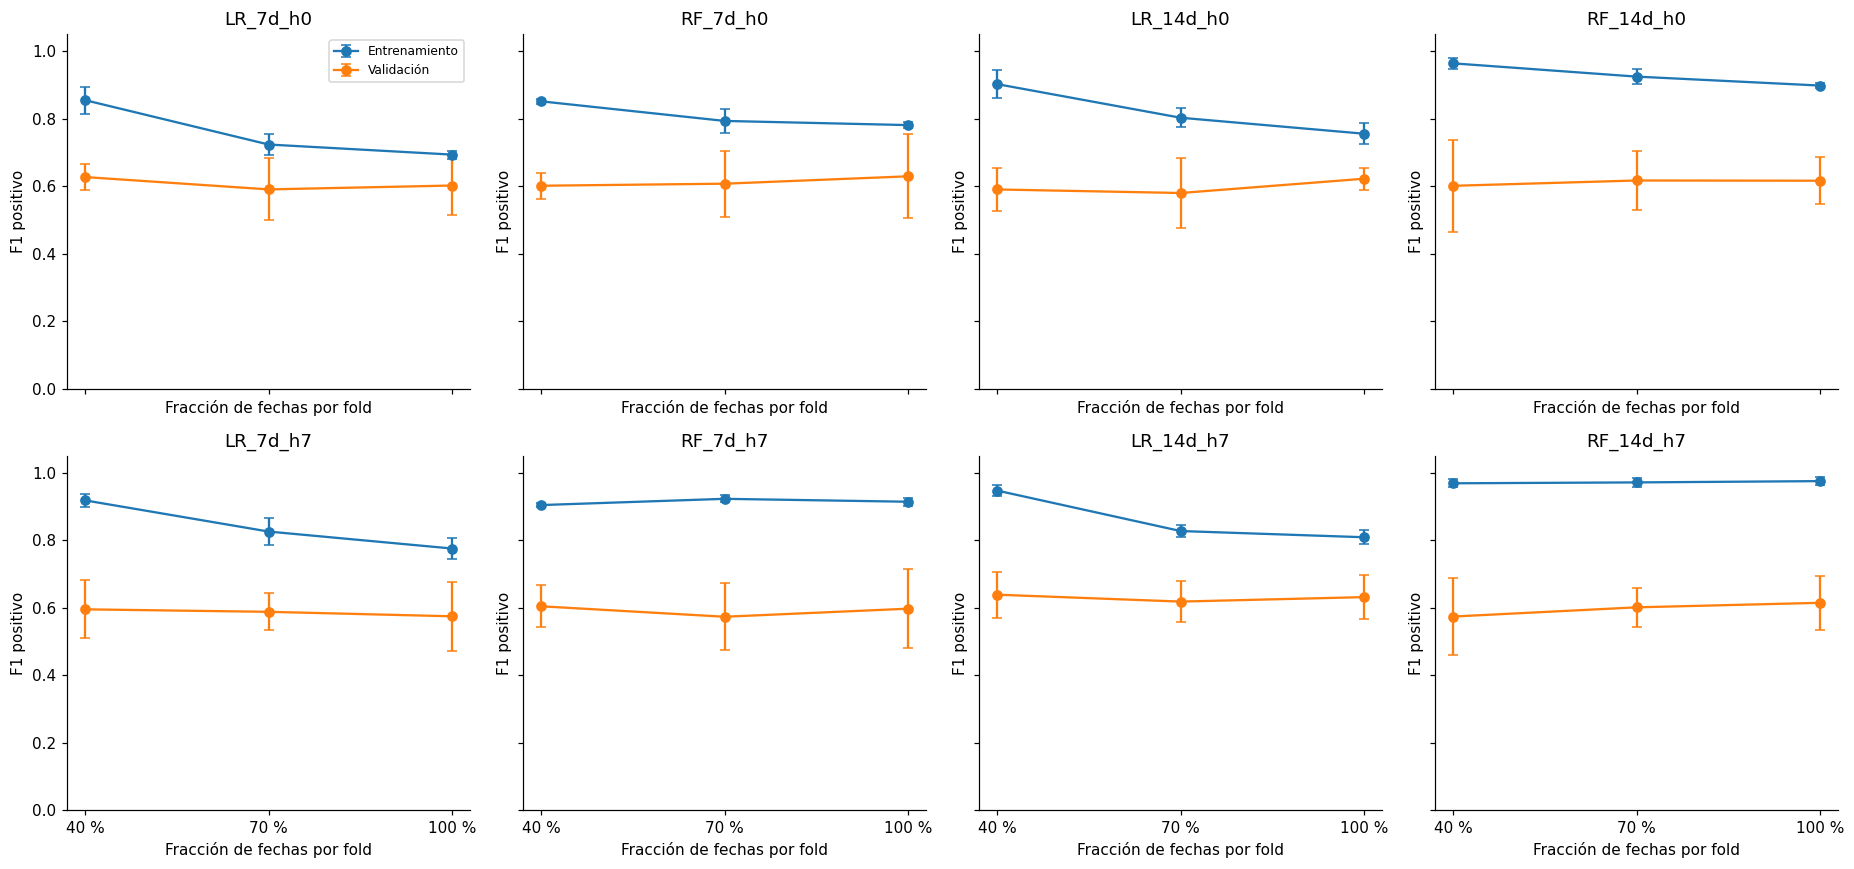

In [9]:
learn_summary = learning[learning.estado.eq('ok')].groupby(['config', 'fraccion']).agg(
    n_medio=('n', 'mean'), n_min=('n', 'min'), n_max=('n', 'max'), folds=('fold', 'nunique'),
    train_f1=('train_f1', 'mean'), train_de=('train_f1', 'std'),
    valid_f1=('validation_f1', 'mean'), valid_de=('validation_f1', 'std')).reset_index()
display(learn_summary.round(3))
display(learning.groupby('estado').size().rename('registros').to_frame())
fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True)
for record, ax in zip(frozen['configs'], axes.flat):
    table = learn_summary[learn_summary.config.eq(record['config'])]
    ax.errorbar(table.fraccion, table.train_f1, yerr=table.train_de, marker='o', capsize=3, label='Entrenamiento')
    ax.errorbar(table.fraccion, table.valid_f1, yerr=table.valid_de, marker='o', capsize=3, label='Validación')
    ax.set(title=record['config'], xlabel='Fracción de fechas por fold', ylabel='F1 positivo', ylim=(0, 1.05))
    ax.set_xticks([.4, .7, 1], labels=['40 %', '70 %', '100 %'])
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

El rendimiento de entrenamiento supera al de validación en las ocho configuraciones al utilizar el entrenamiento completo. Algunas RF muestran brechas amplias, compatibles con sobreajuste y diferencias temporales de distribución, sin que la curva identifique una causa única. Las curvas no crecen de manera uniforme al agregar fechas. Sus barras son dispersión entre folds, no incertidumbre de una nueva campaña; tampoco justifican retocar parámetros después de ver el histórico.

## 9. Ventanas y referencias

Leemos las diferencias descriptivas aprobadas. Un delta positivo de 14d−7d indica mayor F1 con la ventana larga para ese algoritmo y horizonte, sin constituir una prueba de significación. En h7 contrastamos además contra mantener el resultado registrado en t.

In [10]:
differences = pd.read_csv(configured('resultados') / 'diferencias_descriptivas.csv')
display(differences.round(4))
references = comparison[comparison.config.str.startswith(('mayoria', 'persistencia'))]
display(references[['config', 'cv_f1', 'historico_f1', 'historico_precision', 'historico_recall']].round(4))

,horizonte,modelo,comparacion,delta_cv_f1,delta_historico_f1
0,0,LR,14d menos 7d,0.0201,0.0508
1,0,RF,14d menos 7d,-0.0130,-0.0646
2,0,LR_7d_h0,menos mayoria_h0,0.4129,0.3265
3,0,RF_7d_h0,menos mayoria_h0,0.4402,0.3846
4,0,LR_14d_h0,menos mayoria_h0,0.4330,0.3774
5,0,RF_14d_h0,menos mayoria_h0,0.4272,0.3200
6,7,LR,14d menos 7d,0.0568,0.0404
7,7,RF,14d menos 7d,0.0174,-0.1016
8,7,LR_7d_h7,menos mayoria_h7,-0.0383,0.4444
9,7,LR_7d_h7,menos persistencia_h7,0.0564,-0.2902


,config,cv_f1,historico_f1,historico_precision,historico_recall
8,mayoria_h0,0.1887,0.0000,0.00,0.00
9,mayoria_h7,0.6127,0.0000,0.00,0.00
10,persistencia_h7,0.5180,0.7347,0.72,0.75


En CV, 14 días mejora LR en ambos horizontes y RF en h7; no mejora RF en h0. En la evaluación histórica, las RF de 14 días empeoran frente a sus versiones de 7 días, mientras LR mejora moderadamente. Por eso no hay una ventaja uniforme de ampliar la ventana.

Persistencia h7 alcanza F1 ≈0,735 y recall 0,75 en el histórico, superiores a los de la LR seleccionada. Esta comparación limita la evidencia de valor adicional de los resúmenes climáticos frente a conocer el estado actual. No sustituimos el modelo seleccionado ni cambiamos el experimento después de observar ese resultado.

## Discusión y conclusiones

1. La validación seleccionó RF de 7 días para h0 y LR de 14 días para h7. Conservamos esa selección y sus parámetros.
2. Los modelos seleccionados muestran recall histórico bajo. Estos resultados no respaldan una alerta agronómica ni una recomendación de manejo.
3. H0 clasifica un estado registrado actual. H7 predice experimentalmente el estado registrado siete días después e incluye positivos previos; no identifica exclusivamente nuevas infecciones o primeras detecciones.
4. `fecha_registro` coincide con `primera_consulta`; no se confirmó fecha de muestreo ni disponibilidad de todas las etiquetas al emitir una predicción. ERA5 es retrospectivo. La ausencia técnica de solapamiento no resuelve esa limitación operacional.
5. Las ubicaciones se repiten, la cobertura es desigual y algunas comparten coordenadas o celdas meteorológicas. La prueba temporal no acredita transferencia geográfica. Los horizontes tienen poblaciones diferentes y el histórico es pequeño y previamente observado.
6. Las puntuaciones no están validadas como probabilidades calibradas de aparición de roya. Las asociaciones meteorológicas no demuestran causalidad.

Una futura evaluación prospectiva necesitaría fechas de muestreo y publicación verificadas, protocolo de confirmación de etiquetas y datos realmente inéditos, reservados antes de analizarlos. Este trabajo mantiene el alcance retrospectivo aprobado y no realiza ajustes nuevos a partir de la evaluación histórica.

## Fuentes y reproducción

- Etiquetas: [Epagri/CIRAM Agroconnect](https://ciram.epagri.sc.gov.br/agroconnect/), endpoint `busca-doenca-munic.jsp`. Redistribución pendiente de aclaración; registros individuales locales.
- Meteorología: [Open-Meteo Historical Weather](https://open-meteo.com/en/docs/historical-weather-api), ERA5, atribución [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Transformaciones: agregación horaria → diaria → ventanas y componentes del viento.
- Código oficial: `scripts/procesar_datos.py`, `entrenar.py`, `evaluar.py` y `verificar.py`. Configuración: `scripts/proyecto.json`. Entorno: `requirements.txt` y `results/entorno.json`.
- Evidencias: `results/seleccion.json`, `secuencia.json`, `busquedas/` y manifiestos en `data/huellas.json`. Los datos y modelos locales autorizados son necesarios para la comprobación técnica completa, pero no para ejecutar este notebook.

Para repetir únicamente la comprobación usamos `python scripts/verificar.py`. El ajuste completo, separado de la ejecución de este notebook, se realiza con `scripts/entrenar.py` y después `scripts/evaluar.py`, siempre en una raíz de reproducción nueva. La lógica y los comandos técnicos están documentados en `README.md`.